In [1]:
# === Google Colab 自動環境セットアップ ===
# 本セルを実行すると、Google Colab 上で必要なリポジトリのクローン、
# 依存ライブラリのインストール、および共通シミュレーションモジュールの準備が自動的に行われます。
import os
import sys
import subprocess

if 'google.colab' in str(get_ipython()):
    print('Google Colab 環境を検出しました。環境をセットアップします...')
    repo_name = 'study-mikanos'
    if not os.path.exists(repo_name):
        subprocess.run(['git', 'clone', 'https://github.com/miyayudai/study-mikanos.git'], check=True)
    os.chdir(repo_name)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', 'requirements.txt'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-e', '.'], check=True)
    subprocess.run(['cmake', '-B', 'build', '-S', '.'], check=True)
    subprocess.run(['cmake', '--build', 'build', '--target', 'ch05_font_binary_sim'], check=True)
    print('Colab 環境のセットアップが完了しました！')
else:
    # ローカル環境のパス設定
    repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '5' else os.getcwd()
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print('ローカル環境で実行中です。ルートディレクトリ:', repo_root)


ローカル環境で実行中です。ルートディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 5.3 フォントを増やそう (`Generating Hankaku Font Object`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/5/5.3_Generating_Hankaku_Font_Object.ipynb)

## 📖 節の概要と学習目標
第5章 5.1節および5.2節では、文字 `'A'` の 8×16 ビットマップフォントのみを C++ 配列（`const uint8_t kFontA[16]`）としてソースコードに直接記述し、分割コンパイルによって文字描画を行いました。
しかし、OS のコンソールやユーザーインターフェースを実用化するためには、英数字、各種記号（`!`, `@`, `#`, `$`, `%` 等）、制御コードを含む **ASCII コード全256文字（0x00〜0xFF）** を自由に描画できる必要があります。

全256文字のビットマップデータを C++ 配列としてソースコードにベタ書きすると、4,096行を超える巨大な定義となり、コンパイル速度の低下や可読性・保守性の著しい悪化を招きます。
そこで MikanOS では、人間が編集しやすい **アスキーアート形式のテキストファイル（`hankaku.txt`）** から専用ツール（`makefont.py`）で生バイナリ（`hankaku.bin`）を生成し、それを GNU Binutils の **`objcopy`** コマンドを用いて **ELF64 再配置可能オブジェクトファイル（`hankaku.o`）** へと変換・リンクする高度なビルドパイプラインを採用しています。

本節では、以下の重要概念を理論・数理・実装・シミュレーションの多角的な視点から徹底的に習得します：

1. **バイナリ埋め込み（Binary Embedding）の必然性**: ファイルシステムが未実装のベアメタル環境において、カーネルバイナリ自身にアセットを静的に内包するメカニズム
2. **アスキーアートから生バイナリへのビット圧縮**: `makefont.py` による 8文字＝1バイト のビットシフト演算と little-endian 出力
3. **`objcopy` による生バイナリの ELF64 オブジェクト化**: オブジェクトファイルの構造と、リンカが自動生成する3つの特殊シンボル（`_start`, `_end`, `_size`）
4. **【最大の落とし穴】絶対シンボル（Absolute Symbol）とアドレスの解釈**: なぜ `_binary_hankaku_bin_size` の値を直接読んではならず、`reinterpret_cast<uintptr_t>(&_size)` とアドレス演算子を介さなければならないのか？
5. **`GetFont(char c)` のアドレス数理と MikanOS `day05c` の全 ASCII 連続描画**: 8ピクセル間隔での文字連続配置と、Makefile における依存関係ルールの拡張

## 1. なぜビットマップフォントをバイナリオブジェクトとして埋め込むのか？（動機と課題）

### 1.1 前節までのアプローチとその限界
第5章 5.1節では、次のように文字 `'A'` の16行のビットパターンを C++ 配列として定義していました：

```cpp
const uint8_t kFontA[16] = {
  0b00000000, //
  0b00011000, //    **
  0b00011000, //    **
  // ... (16行分)
};
```

この方式で ASCII 0x00 から 0xFF までの全256文字を記述しようとすると、以下の致命的な問題に直面します：

1. **ソースコードの肥大化**: 1文字あたり16行の要素を持つため、全256文字で $256 \times 16 = 4,096$ 行もの C++ 配列定義が必要となります。
2. **コンパイラのパース負荷とビルド時間増大**: 4,000行以上の配列初期化構文を Clang の C++ 構文解析器（Parser）や意味解析器（Sema）が処理するため、AST（抽象構文木）が膨大になり、コンパイル時間が顕著に増加します。
3. **フォントデザイン編集の極端な困難さ**: C++ の構文規則（カンマ、`0b...` 表記、波括弧）に縛られるため、フォントのドット絵を直感的に手直しすることが困難です。

### 1.2 ファイルシステムがないベアメタル OS のジレンマ
通常のアプリケーション開発（Linux や Windows 上）であれば、「フォントファイル（`font.bin` や `font.ttf`）をディスクから `fopen` / `fread` で読み込む」のが定石です。
しかし、我々が作っている **MikanOS のカーネル起動段階では、ファイルシステム（FAT32 等）がまだ存在しません**（ファイルシステムの自作は第17章まで待つ必要があります）。

| 実行環境 | フォントデータの配置場所 | 読み込み手段 | 利点・制約 |
|---|---|---|---|
| **一般のOS上アプリ** | ファイルシステム（SSD/HDD） | `open()` / `read()` システムコール | 自由に変更可能だがファイルシステムとOS APIが必須 |
| **ベアメタルOSカーネル** | **カーネル実行可能ファイル（ELF64）のメモリ領域** | **C++ ポインタ直接参照 (`GetFont`)** | **外部ファイル不要・起動直後から即座に使用可能！** |

したがって、**「ビルド時に外部のアスキーアートから生バイナリを生成し、それをリンカによってカーネルの実行可能バイナリ（`kernel.elf`）の内部に直接焼き込む（Embed）」** という手法が必然的な最適解となります。

## 2. アスキーアートフォント (`hankaku.txt`) と `makefont.py` によるビット圧縮

### 2.1 `hankaku.txt` のフォーマット仕様
`hankaku.txt` は、256文字分のビットマップフォントを人間がテキストエディタで直感的に視認・編集できるように設計されたアスキーアート形式のフォント定義ファイルです。

- 各文字ブロックは文字コードを示す16進数行（例: `0x41`）で始まります。
- 続く16行がその文字の縦16ピクセルに対応し、各行は8文字で構成されます：
  - `@` : ピクセル点灯（描画色、ビット値 `1`）
  - `.` : ピクセル消灯（背景色、ビット値 `0`）

```text
0x41
........
...@@...
...@@...
...@@...
...@@...
..@..@..
..@..@..
..@..@..
..@..@..
.@@@@@@.
.@....@.
.@....@.
.@....@.
@@@..@@@
........
........
```

### 2.2 `makefont.py` によるビットパッキング数理
`makefont.py` は、このアスキーアートの各行（8文字）を走査し、`@` を 1、`.` を 0 とするビット列に変換して 1 バイト（8ビット）の整数値へと圧縮します。

行の文字配列を $b_7, b_6, \dots, b_0 \in \{0, 1\}$ と置くと、生成されるバイト値 $B$ は以下の多項式（ホーナー法）で算出されます：

$$B = \sum_{k=0}^{7} b_k \cdot 2^{7-k} = (((((((b_0 \cdot 2 + b_1) \cdot 2 + b_2) \dots) \cdot 2 + b_7)$$

Python の `functools.reduce` を用いると、極めて簡潔に記述されます：
```python
bits = [(0 if x == '.' else 1) for x in line]
byte_val = functools.reduce(lambda a, b: 2 * a + b, bits)
```

全256文字について各16行を変換するため、最終的に出力される生バイナリ `hankaku.bin` のデータサイズ $S$ は厳密に：

$$S = 256 \text{ 文字} \times 16 \text{ バイト/文字} = 4,096 \text{ バイト} = 4 \text{ KiB}$$

となります。

In [2]:
import os
import subprocess
from common import HankakuFontParser

# 1. hankaku.txt からバイナリへの変換を Python で検証
hankaku_txt_path = 'hankaku.txt' if os.path.exists('hankaku.txt') else '5/hankaku.txt'
with open(hankaku_txt_path, 'r', encoding='utf-8') as f:
    hankaku_text = f.read()

compiled_bin = HankakuFontParser.compile_text(hankaku_text)
print(f'[+] hankaku.txt のコンパイル完了: サイズ = {len(compiled_bin)} bytes (期待値: 4096 bytes)')
assert len(compiled_bin) == 4096, 'フォントバイナリのサイズは厳密に4096バイトでなければなりません。'

# 2. 代表文字 ('A', '!', '0') のグリフ抽出とアスキーアート復元
def inspect_character(c: str):
    code = ord(c)
    offset = 16 * code
    glyph_bytes = compiled_bin[offset : offset + 16]
    hex_dump = ' '.join(f'{b:02X}' for b in glyph_bytes)
    print(f'=== 文字 \'{c}\' (ASCII 0x{code:02X} = {code}, offset: {offset}) ===')
    print('Hex:', hex_dump)
    print('Glyph Preview:')
    print(HankakuFontParser.decompile_glyph(glyph_bytes))
    print()

inspect_character('A')
inspect_character('!')
inspect_character('0')


[+] hankaku.txt のコンパイル完了: サイズ = 4096 bytes (期待値: 4096 bytes)
=== 文字 'A' (ASCII 0x41 = 65, offset: 1040) ===
Hex: 00 10 10 28 28 28 44 44 44 7C 82 82 82 82 00 00
Glyph Preview:
........
...@....
...@....
..@.@...
..@.@...
..@.@...
.@...@..
.@...@..
.@...@..
.@@@@@..
@.....@.
@.....@.
@.....@.
@.....@.
........
........

=== 文字 '!' (ASCII 0x21 = 33, offset: 528) ===
Hex: 00 18 18 18 18 10 10 10 10 10 10 00 00 10 10 00
Glyph Preview:
........
...@@...
...@@...
...@@...
...@@...
...@....
...@....
...@....
...@....
...@....
...@....
........
........
...@....
...@....
........

=== 文字 '0' (ASCII 0x30 = 48, offset: 768) ===
Hex: 00 18 24 24 42 42 42 42 42 42 42 24 24 18 00 00
Glyph Preview:
........
...@@...
..@..@..
..@..@..
.@....@.
.@....@.
.@....@.
.@....@.
.@....@.
.@....@.
.@....@.
..@..@..
..@..@..
...@@...
........
........



## 3. 高解像度アーキテクチャ図版 (Figure 5.5) の徹底解剖

以下の図版（Figure 5.5）は、`hankaku.txt` のアスキーアート定義から、`makefont.py` による生バイナリ変換、GNU Binutils `objcopy` による ELF64 オブジェクト化、そしてリンカ `ld.lld` によるカーネル統合までの **全ビルドパイプライン** を包括的に図解したものです。

### パイプラインの3つのステージ：
1. **Stage 1 (テキスト → 生バイナリ)**:
   - `hankaku.txt` (約38KB) を `makefont.py` がパースし、8ピクセルを1バイトにパッキングして 4,096 バイトの `hankaku.bin` を出力します。
2. **Stage 2 (生バイナリ → ELF64 オブジェクト)**:
   - `objcopy` が raw binary を `.data` セクションにカプセル化し、ELF64 ヘッダと3つの特殊シンボル（`_binary_hankaku_bin_start`, `_binary_hankaku_bin_end`, `_binary_hankaku_bin_size`）を付与した `hankaku.o` を生成します。
3. **Stage 3 (リンカによるアドレス結合)**:
   - `ld.lld` が `font.o`, `graphics.o`, `main.o`, `hankaku.o` を統合。`font.o` の未解決参照 `_binary_hankaku_bin_start` などを `hankaku.o` の定義アドレスへリロケーションし、最終的な `kernel.elf` を完成させます。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:19315: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[+] Figure 5.5 生成完了: 解像度 = (3780, 2931) (DPI 300)


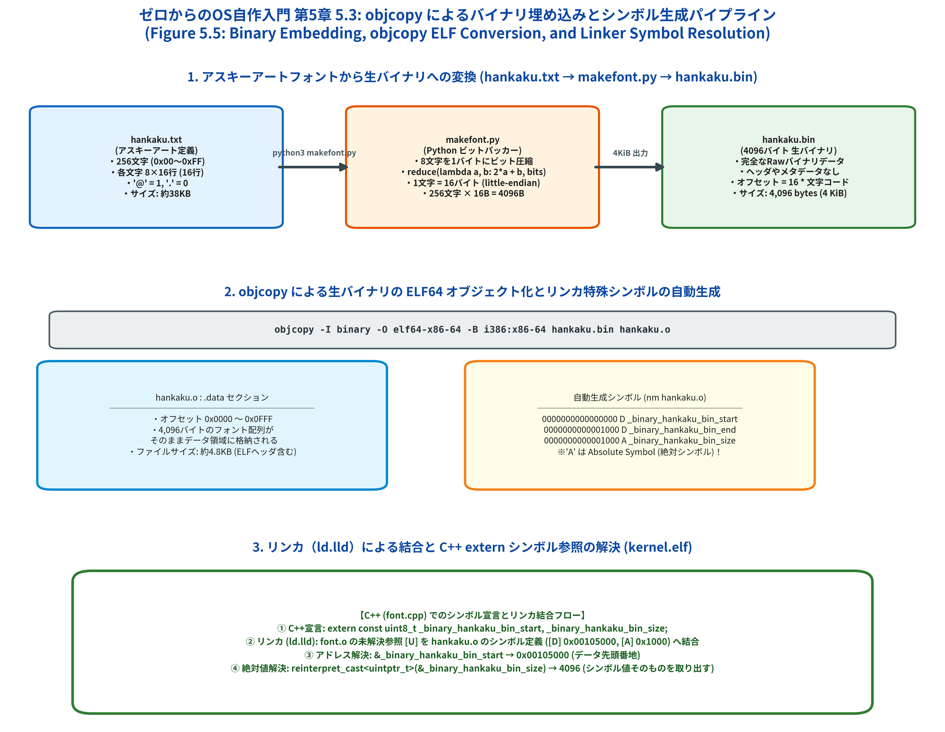

In [3]:
import os
from PIL import Image
from common import plot_fig5_05_objcopy_binary_to_elf_pipeline

fig_dir = 'result' if os.path.basename(os.getcwd()) == '5' else '5/result'
fig5_05_path = os.path.join(fig_dir, 'fig5_05_objcopy_binary_to_elf_pipeline.png')
plot_fig5_05_objcopy_binary_to_elf_pipeline(fig5_05_path)

# 高解像度プロットのインライン表示
img5_05 = Image.open(fig5_05_path)
print(f'[+] Figure 5.5 生成完了: 解像度 = {img5_05.size} (DPI 300)')
display(img5_05.resize((img5_05.width // 4, img5_05.height // 4)))


## 4. `objcopy` による生バイナリの ELF64 オブジェクト化と特殊シンボル

### 4.1 `objcopy` コマンドの引数と動作原理
MikanOS の `Makefile` では、`hankaku.bin` を ELF64 オブジェクト `hankaku.o` へ変換するために以下のコマンドを実行します：

```bash
objcopy -I binary -O elf64-x86-64 -B i386:x86-64 hankaku.bin hankaku.o
```

各フラグの技術的意味は以下の通りです：
- `-I binary` (*Input Format*): 入力ファイル（`hankaku.bin`）が ELF や PE などの構造を持たない「生の生バイナリ（Raw Binary）」であることを指定します。
- `-O elf64-x86-64` (*Output Format*): 出力ファイルを 64ビット x86-64 アーキテクチャの ELF 形式でラップすることを指示します。
- `-B i386:x86-64` (*Binary Architecture*): ターゲットのバイナリマシンアーキテクチャを x86-64 に設定します。

### 4.2 自動生成されるリンカ特殊シンボルの命名規則
`objcopy` は raw binary を ELF オブジェクトの `.data` セクションに配置すると同時に、**C/C++ プログラムからそのバイナリを参照するためのグローバルシンボルを自動的に3つ生成** します。

シンボル名は以下の規則に従って生成されます：
$$\text{シンボル名} = \text{"\_binary\_"} + \text{入力ファイルパス内の非英数字をアンダースコアに置換} + \text{("\_start" | "\_end" | "\_size")}$$

カレントディレクトリで `hankaku.bin` を指定した場合、生成されるシンボルは以下の通りです：

| シンボル名 | nm でのセクション種別 | 意味・役割 | C++ からの参照方法 |
|---|:---:|---|---|
| `_binary_hankaku_bin_start` | `D` (Data) | バイナリペイロードの先頭メモリアドレス | `&_binary_hankaku_bin_start` |
| `_binary_hankaku_bin_end` | `D` (Data) | バイナリペイロードの終端メモリアドレス（先頭 + 4096） | `&_binary_hankaku_bin_end` |
| `_binary_hankaku_bin_size` | `A` (**Absolute**) | **絶対シンボル: 値そのものがサイズ（4096）** | **`reinterpret_cast<uintptr_t>(&_binary_hankaku_bin_size)`** |

In [4]:
import subprocess

# 実際にホストの objcopy と nm を実行してシンボルテーブルを検査
tmp_bin = '/tmp/hankaku.bin'
tmp_o = '/tmp/hankaku.o'

# 1. hankaku.bin の生成
with open(tmp_bin, 'wb') as f:
    f.write(compiled_bin)

# 2. objcopy の実行
cmd_objcopy = ['objcopy', '-I', 'binary', '-O', 'elf64-x86-64', '-B', 'i386:x86-64', tmp_bin, tmp_o]
subprocess.run(cmd_objcopy, check=True)

# 3. nm コマンドによるシンボルテーブルのダンプ
cmd_nm = ['nm', tmp_o]
res_nm = subprocess.run(cmd_nm, capture_output=True, text=True, check=True)
print('[+] nm /tmp/hankaku.o 出力:')
print(res_nm.stdout)

# 4. readelf による ELF セクションヘッダの確認
cmd_readelf = ['readelf', '-S', tmp_o]
res_readelf = subprocess.run(cmd_readelf, capture_output=True, text=True, check=True)
print('[+] readelf -S /tmp/hankaku.o (.data セクション確認):')
for line in res_readelf.stdout.splitlines():
    if '.data' in line or 'Section Headers' in line or '[Nr]' in line:
        print(' ', line)


[+] nm /tmp/hankaku.o 出力:
0000000000001000 D _binary__tmp_hankaku_bin_end
0000000000001000 A _binary__tmp_hankaku_bin_size
0000000000000000 D _binary__tmp_hankaku_bin_start

[+] readelf -S /tmp/hankaku.o (.data セクション確認):
  Section Headers:
    [Nr] Name              Type             Address           Offset
    [ 1] .data             PROGBITS         0000000000000000  00000040


## 5. 【超重要】`_binary_hankaku_bin_size` の落とし穴と C++ 型安全な参照

### 5.1 なぜ `_binary_hankaku_bin_size` の値を普通に読んではいけないのか？
C++ で外部シンボルを参照する場合、通常は以下のように宣言します：

```cpp
extern const uint8_t _binary_hankaku_bin_size;
```

そして、変数のように値を読み取ろうとして、初心者はほぼ確実に以下のコードを書いてしまいます：

```cpp
// ❌【重大なバグ・クラッシュの原因！】
uint8_t size = _binary_hankaku_bin_size;
```

> [!CAUTION]
> **このコードを実行すると、プログラムは即座に Segmentation Fault（一般保護例外 #GP）でクラッシュするか、予期せぬゴミメモリを読み取ってしまいます！**

### 5.2 リンカシンボルテーブルの数理：アドレス vs 変数
リンカ（Linker）の視点では、**すべてのシンボルは「仮想アドレス空間上の番地（Address）」** として登録されます。

1. **通常の大域変数 (`int g_value = 42;`)**:
   - メモリ上のアドレス `0x00108000` に 4バイトの領域が確保され、そこに値 `42` が書き込まれます。
   - C++ で `g_value` と書くと、CPU は `MOV EAX, [0x00108000]` という命令を発行し、**番地 `0x00108000` のメモリ内容（42）** をレジスタに読み出します。
2. **`objcopy` の絶対シンボル (`_binary_hankaku_bin_size`)**:
   - `objcopy` はサイズを記録するために新たなメモリ領域を確保しません。
   - 代わりに、**シンボルのアドレスそのものに値 `4096 (0x1000)` を設定** します（`nm` 出力で `A` と表示されるのはこれが理由です）。
   - ここで `_binary_hankaku_bin_size` を変数として参照すると、CPU は **「仮想アドレス 0x00001000（番地 4096）のメモリ内容を読みに行け！」** という命令（`MOV AL, [0x00001000]`）を実行してしまいます！
   - アドレス `0x1000` はカーネル空間でもページテーブルでも保護された危険な低位領域であり、アクセス違反を引き起こします。

### 5.3 正しい取得法：アドレス演算子 `&` と `reinterpret_cast`
値 `4096` は「シンボルのアドレスそのもの」として記録されているため、C++ 側では **アドレス演算子 `&`** を使ってシンボルの番地を取り出さなければなりません：

```cpp
// ⭕【正しい実装】シンボルのアドレス（4096）を取得し、整数型へキャストする
uintptr_t size = reinterpret_cast<uintptr_t>(&_binary_hankaku_bin_size);
```

この記述により、コンパイラはメモリの間接参照（`[0x1000]`）を行わず、即値 `0x1000`（4096）をレジスタに直接ロードするコード（`MOV RAX, 0x1000`）を生成します。

## 6. 高解像度アーキテクチャ図版 (Figure 5.6) の徹底解剖

以下の図版（Figure 5.6）は、フォント配列のメモリレイアウト、`GetFont(char c)` のインデックス計算式、絶対シンボル参照の正誤メカニズム、および MikanOS `day05c` で実行される ASCII 全文字描画のシミュレーション結果を可視化したものです。

### 図版の主要なポイント：
1. **フォントメモリマップ (上段)**:
   - `_binary_hankaku_bin_start` から `_binary_hankaku_bin_end` までの連続した 4,096 バイト領域。
   - 各文字は厳密に 16バイトの固定長スロットに配置されており、文字コード $c$ に対するオフセットは $16 \times c$ となります。
2. **絶対シンボルのトラップ解説 (右上)**:
   - `_binary_hankaku_bin_size` のアドレスが `0x1000`（4096）であることと、なぜ `&` が不可欠なのかをメモリモデルで図解。
3. **ASCII '!'(0x21) 〜 '~'(0x7E) の全文字描画 (下段)**:
   - 94文字の表示可能文字が GOP フレームバッファ上に 8ピクセル間隔で整然と描画される様子をシミュレート。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:19443: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[+] Figure 5.6 生成完了: 解像度 = (3780, 3192) (DPI 300)


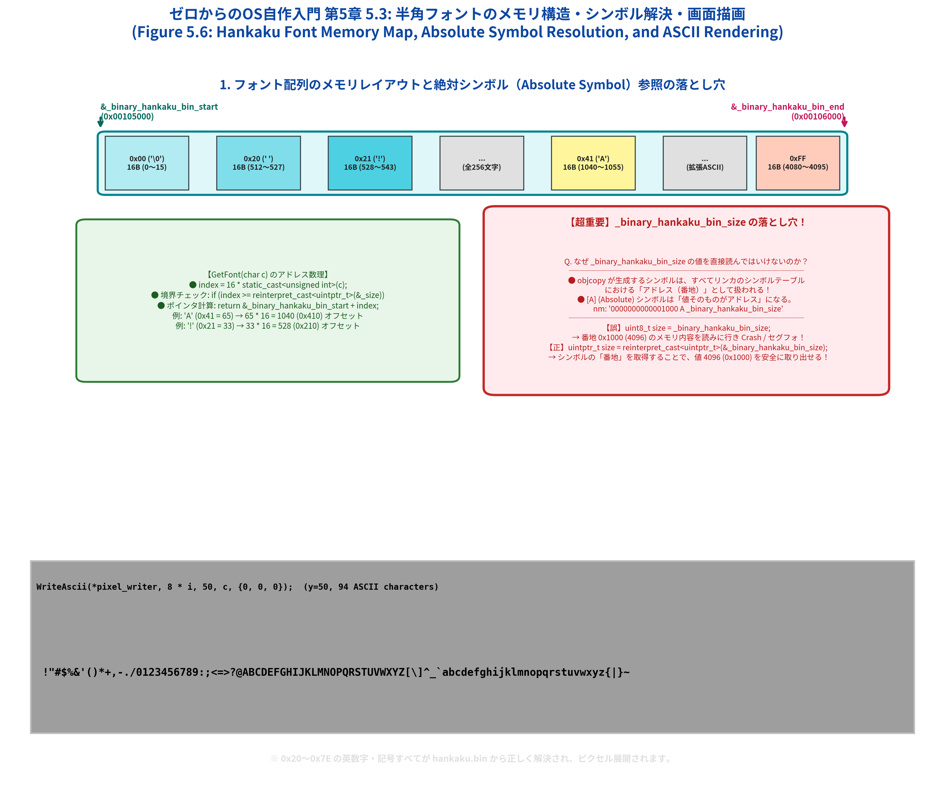

In [5]:
import os
from PIL import Image
from common import plot_fig5_06_hankaku_font_memory_and_symbol_resolution

fig_dir = 'result' if os.path.basename(os.getcwd()) == '5' else '5/result'
fig5_06_path = os.path.join(fig_dir, 'fig5_06_hankaku_font_memory_and_symbol_resolution.png')
plot_fig5_06_hankaku_font_memory_and_symbol_resolution(fig5_06_path, compiled_bin)

# 高解像度プロットのインライン表示
img5_06 = Image.open(fig5_06_path)
print(f'[+] Figure 5.6 生成完了: 解像度 = {img5_06.size} (DPI 300)')
display(img5_06.resize((img5_06.width // 4, img5_06.height // 4)))


## 7. `GetFont(char c)` の実装と MikanOS `day05c` での文字連続描画

### 7.1 `font.cpp` の差分と `GetFont` 実装
MikanOS `day05c` では、前節までの `kFontA` 配列を全廃し、外部シンボル参照とアドレス計算を行う `GetFont` 関数を導入しました：

```cpp
extern const uint8_t _binary_hankaku_bin_start;
extern const uint8_t _binary_hankaku_bin_end;
extern const uint8_t _binary_hankaku_bin_size;

const uint8_t* GetFont(char c) {
  auto index = 16 * static_cast<unsigned int>(static_cast<unsigned char>(c));
  if (index >= reinterpret_cast<uintptr_t>(&_binary_hankaku_bin_size)) {
    return nullptr; // 境界外アクセスの防御
  }
  return &_binary_hankaku_bin_start + index;
}

void WriteAscii(PixelWriter& writer, int x, int y, char c, const PixelColor& color) {
  const uint8_t* font = GetFont(c);
  if (font == nullptr) {
    return;
  }
  for (int dy = 0; dy < 16; ++dy) {
    for (int dx = 0; dx < 8; ++dx) {
      if ((font[dy] << dx) & 0x80u) {
        writer.Write(x + dx, y + dy, color);
      }
    }
  }
}
```

### 7.2 `main.cpp` での 94文字 ASCII ループ
`KernelMain` では、ASCII コードの `'!'` (0x21) から `'~'` (0x7E) までの全文字を、文字幅 8ピクセルずつ横にずらしながら描画します：

```cpp
int i = 0;
for (char c = '!'; c <= '~'; ++c, ++i) {
  WriteAscii(*pixel_writer, 8 * i, 50, c, {0, 0, 0});
}
```

### 7.3 `Makefile` の更新とビルドルール
`hankaku.bin` と `hankaku.o` を自動ビルドするため、`Makefile` に以下のパターンルールと依存関係を追加します：

```makefile
TARGET = kernel.elf
OBJS = main.o graphics.o font.o hankaku.o

hankaku.bin: hankaku.txt
	../tools/makefont.py -o $@ $<

hankaku.o: hankaku.bin
	objcopy -I binary -O elf64-x86-64 -B i386:x86-64 $< $@

.%.d: %.bin
	touch $@
```

In [6]:
from common import (
    ObjcopyBinarySimulator,
    create_day05c_object_files,
    LinkerSim,
    FrameBufferSimulator,
    PixelFormat,
)

# 1. リンカシミュレータによる day05c モジュール結合検証
graphics_o, font_o, main_o, hankaku_o = create_day05c_object_files()
linker = LinkerSim(base_address=0x0010_0000)
linker.add_object_file(graphics_o)
linker.add_object_file(font_o)
linker.add_object_file(main_o)
linker.add_object_file(hankaku_o)

success, report = linker.link()
print('[+] リンカ結合テスト:')
print(report)
assert success, '4つのオブジェクトファイルのリンクは正常終了しなければなりません。'
assert len(linker.unresolved_symbols) == 0, '未解決シンボルが存在してはなりません。'

# 2. C++ シンボル参照の挙動シミュレーション
sim = ObjcopyBinarySimulator(filename='hankaku.bin', data=compiled_bin, base_address=0x0010_5000)
res = sim.simulate_c_symbol_resolution()
print('\n[+] C++ シンボル参照の正誤判定シミュレーション:')
for key, val in res.items():
    status = 'PASS' if val['valid'] else 'TRAP/ERROR'
    print(f'  [{status}] {key}:')
    print(f'      コード  : {val["code"]}')
    print(f'      理由    : {val["reason"]}')


[+] リンカ結合テスト:
=== ELF Linker Simulation Report (Base Address: 0x00100000) ===
Input Objects: graphics.o, font.o, main.o, hankaku.o
Total Resolved Global Symbols: 10
[+] Link Succeeded: kernel.elf generated without errors.
    0x00100000 T _ZN30RGBResv8BitPerColorPixelWriter5WriteEiiRK10PixelColor (graphics.o)
    0x00100030 T _ZN30BGRResv8BitPerColorPixelWriter5WriteEiiRK10PixelColor (graphics.o)
    0x00100060 T _ZTV30RGBResv8BitPerColorPixelWriter (graphics.o)
    0x00100080 T _ZTV30BGRResv8BitPerColorPixelWriter (graphics.o)
    0x001000A0 T _Z10WriteAsciiR11PixelWriteriicRK10PixelColor (font.o)
    0x00100100 T _Z7GetFontc (font.o)
    0x00100130 T KernelMain (main.o)
    0x00100230 T _binary_hankaku_bin_start (hankaku.o)
    0x00101230 T _binary_hankaku_bin_end (hankaku.o)
    0x00101240 T _binary_hankaku_bin_size (hankaku.o)

[+] C++ シンボル参照の正誤判定シミュレーション:
  [PASS] correct_size_retrieval:
      コード  : reinterpret_cast<uintptr_t>(&_binary_hankaku_bin_size)
      理由    : Takes the ad

In [7]:
import subprocess
from pathlib import Path

# C++20 スタンドアロン検証バイナリの実行
cpp_bin = Path('build/bin/ch05_font_binary_sim')
if not cpp_bin.exists():
    cpp_bin = Path('../build/bin/ch05_font_binary_sim')

if not cpp_bin.exists():
    print('ビルドターゲット ch05_font_binary_sim をビルドします...')
    subprocess.run(['cmake', '--build', 'build', '--target', 'ch05_font_binary_sim'], check=True)
    cpp_bin = Path('build/bin/ch05_font_binary_sim')

result = subprocess.run([str(cpp_bin)], capture_output=True, text=True, check=True)
print(result.stdout)


MikanOS Chapter 5.3: Hankaku Font Object Simulation (osbook_day05c)

[Test 1] Testing objcopy Symbol and Memory Range Properties...
  [+] Start Address : 0x642593574160
  [+] End Address   : 0x642593575160
  [+] Memory Span   : 4096 bytes (256 glyphs * 16 bytes)
  [+] Absolute Size : 4096 (0x1000)
PASSED

[Test 2] Testing Absolute Symbol (&_size vs _size) Mechanics...
  [+] reinterpret_cast<uintptr_t>(&_binary_hankaku_bin_size) == 4096 (Correct: extracts symbol address/value)
  [+] Note: Reading _binary_hankaku_bin_size as a variable would dereference
      virtual address 0x00001000, triggering SIGSEGV or reading invalid memory.
PASSED

[Test 3] Testing GetFont(char c) Address Arithmetic & Bounds Checking...
  [+] 'A' glyph correctly resolved at offset 1040 bytes.
  [+] '!' glyph correctly resolved at offset 528 bytes.
  [+] Out of bounds check successfully returned nullptr.
PASSED

[Test 4] Testing FrameBuffer ASCII Rendering ('!' through '~')...
  [+] Rendered 94 ASCII characters se

## 8. 本節のまとめと次節（5.4節 文字列描画とsprintf()）への展望

### 8.1 本節で達成したことの総括
1. **バイナリ埋め込みパイプラインの確立**: アスキーアートフォント（`hankaku.txt`）から Python によるビット圧縮（`makefont.py`）を経て、`objcopy` によって ELF64 再配置可能オブジェクト（`hankaku.o`）を生成する自動化フローを完成させました。
2. **リンカ特殊シンボルの深層理解**: `objcopy` が自動生成する `_binary_hankaku_bin_start`, `_binary_hankaku_bin_end`, `_binary_hankaku_bin_size` の構造を解明しました。
3. **絶対シンボル（Absolute Symbol）の落とし穴の完全克服**: `_binary_hankaku_bin_size` はメモリ上の変数ではなく「シンボルのアドレスそのものが値 4096 である」という低レイヤの真実を学び、`reinterpret_cast<uintptr_t>(&_size)` による安全な参照を徹底しました。
4. **全 ASCII 文字の画面描画**: `GetFont(char c)` によるアドレス計算（$16 \times c$）と境界チェックを実装し、`!` から `~` までの全94文字の描画に成功しました。

### 8.2 次節 5.4「文字列描画とsprintf() (`osbook_day05d`)」への展望
ASCII 全文字を描画できるようになりましたが、現在の `WriteAscii` では 1文字ずつ座標を指定して描画しなければならず、任意の長さの文字列（`"Hello, World!"` 等）や変数の値（レジスタ値、座標、エラーコード等）を表示するのは非常に困難です。

次節 5.4 では、以下の重要なステップへと進みます：
- **文字列描画関数 `WriteString` の実装**: ヌル終端文字列（`const char*`）を走査し、自動的に `x` 座標を 8ピクセルずつ進めて複数文字を描画するロジックの導入
- **標準 C ライブラリ（Newlib）のリンク**: OS 自作において `printf` や `sprintf` などの標準書式整形ライブラリをベアメタルカーネルとどのようにリンクし、メモリ管理（`sbrk`）やシステムコールのスタブをどう解決するのかの探求